Total data setelah cleaning: 4017 baris

Distribusi kelas:
CUACA
Berawan    2182
Hujan      1032
Cerah       803
Name: count, dtype: int64

Persentase:
CUACA
Berawan    54.319144
Hujan      25.690814
Cerah      19.990042
Name: proportion, dtype: float64

Data latih : 3213 baris
Data uji   : 804 baris

🎯 Akurasi Model: 70.77%

📊 Classification Report:
              precision    recall  f1-score   support

     Berawan       0.75      0.77      0.76       437
       Cerah       0.74      0.89      0.81       161
       Hujan       0.55      0.43      0.48       206

    accuracy                           0.71       804
   macro avg       0.68      0.70      0.68       804
weighted avg       0.70      0.71      0.70       804


📈 Cross Validation: 70.08% (+/- 1.39%)


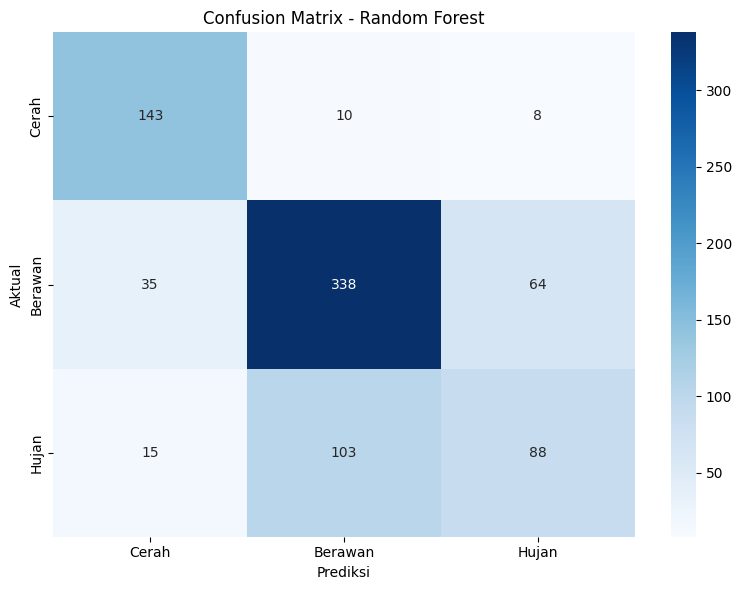

✅ Confusion matrix tersimpan!

📊 Feature Importance:
              Fitur  Importance
11  CLEAR_SKY_RATIO    0.224529
5             SOLAR    0.133629
3            RH_AVG    0.113452
9     HUMIDITY_HEAT    0.097627
7        TEMP_RANGE    0.066942
6       SOLAR_CLEAR    0.066530
8      TEMP_AVG_HUM    0.062159
1                TX    0.058612
10        WIND_TEMP    0.049661
2              TAVG    0.048419
0                TN    0.048002
4            FF_AVG    0.030437


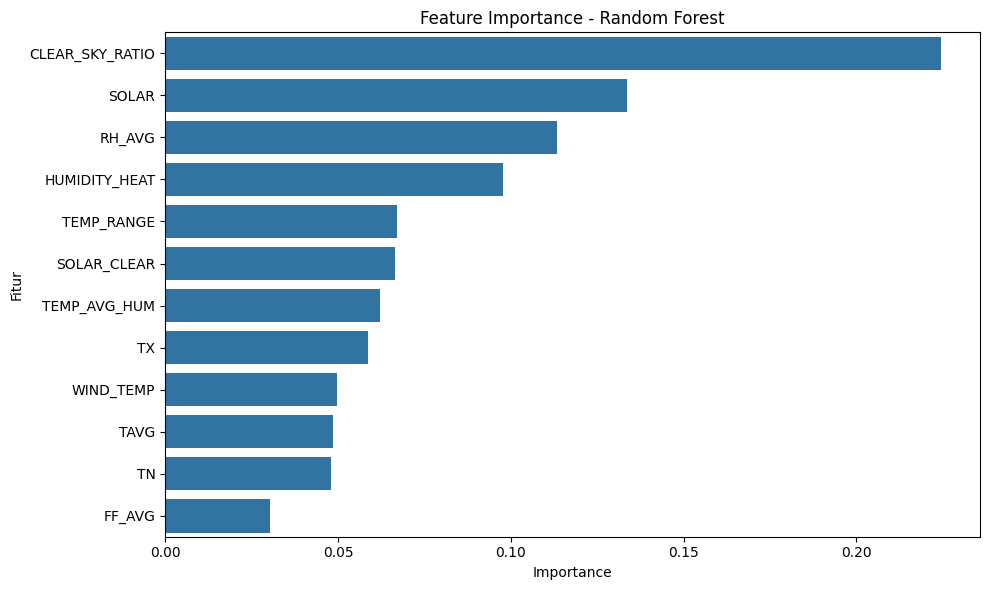

✅ Model final tersimpan!


In [24]:
import pandas as pd
import numpy as np
import os
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt

# ==============================
# 1. LOAD DATA NASA POWER
# ==============================
df = pd.read_csv('../dataset/nasa_power_pekanbaru_2015_2026.csv', skiprows=16)

# Rename kolom
df = df.rename(columns={
    'T2M'                : 'TAVG',
    'T2M_MAX'            : 'TX',
    'T2M_MIN'            : 'TN',
    'RH2M'               : 'RH_AVG',
    'PRECTOTCORR'        : 'RR',
    'WS2M'               : 'FF_AVG',
    'ALLSKY_SFC_SW_DWN'  : 'SOLAR',
    'CLRSKY_SFC_SW_DWN'  : 'SOLAR_CLEAR'
})

# Hapus kolom YEAR dan DOY
df = df[['TN','TX','TAVG','RH_AVG','RR','FF_AVG','SOLAR','SOLAR_CLEAR']]

# ==============================
# 2. CLEANING
# ==============================
df.replace(-999, np.nan, inplace=True)
df.dropna(inplace=True)

print(f"Total data setelah cleaning: {len(df)} baris")

# ==============================
# 3. FEATURE ENGINEERING
# ==============================
df['TEMP_RANGE']      = df['TX'] - df['TN']
df['TEMP_AVG_HUM']    = df['TAVG'] * df['RH_AVG']
df['HUMIDITY_HEAT']   = df['RH_AVG'] / df['TAVG']
df['WIND_TEMP']       = df['FF_AVG'] * df['TAVG']
df['CLEAR_SKY_RATIO'] = df['SOLAR'] / df['SOLAR_CLEAR']

# ==============================
# 4. LABELING (3 KELAS)
# ==============================
def label_cuaca(row):
    rr    = row['RR']
    ratio = row['CLEAR_SKY_RATIO']

    if rr > 10:
        return 'Hujan'
    elif rr >= 3:
        return 'Berawan'
    elif ratio >= 0.8:
        return 'Cerah'
    else:
        return 'Berawan'

df['CUACA'] = df.apply(label_cuaca, axis=1)

print("\nDistribusi kelas:")
print(df['CUACA'].value_counts())
print("\nPersentase:")
print(df['CUACA'].value_counts(normalize=True) * 100)

# ==============================
# 5. FITUR (NO RR)
# ==============================
X = df[['TN','TX','TAVG','RH_AVG','FF_AVG','SOLAR','SOLAR_CLEAR',
        'TEMP_RANGE','TEMP_AVG_HUM','HUMIDITY_HEAT','WIND_TEMP','CLEAR_SKY_RATIO']]
y = df['CUACA']

# ==============================
# 6. SPLIT
# ==============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\nData latih : {len(X_train)} baris")
print(f"Data uji   : {len(X_test)} baris")

# ==============================
# 7. MODEL FINAL
# (tanpa SMOTE, pakai class_weight='balanced')
# (parameter terbaik dari GridSearchCV)
# ==============================
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42
)

model.fit(X_train, y_train)

# ==============================
# 8. EVALUASI
# ==============================
y_pred = model.predict(X_test)
akurasi = accuracy_score(y_test, y_pred)

print(f"\n🎯 Akurasi Model: {akurasi * 100:.2f}%")
print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred))

# ==============================
# 9. CROSS VALIDATION
# ==============================
scores = cross_val_score(model, X, y, cv=5)
print(f"\n📈 Cross Validation: {scores.mean()*100:.2f}% "
      f"(+/- {scores.std()*100:.2f}%)")

# ==============================
# 10. CONFUSION MATRIX
# ==============================
cm = confusion_matrix(y_test, y_pred,
                      labels=['Cerah','Berawan','Hujan'])

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cerah','Berawan','Hujan'],
            yticklabels=['Cerah','Berawan','Hujan'])
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()

os.makedirs('../img', exist_ok=True)
plt.savefig('../img/confusion_matrix.png', dpi=300)
plt.show()
print("✅ Confusion matrix tersimpan!")

# ==============================
# 11. FEATURE IMPORTANCE
# ==============================
feat_importance = pd.DataFrame({
    'Fitur'     : X.columns,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n📊 Feature Importance:")
print(feat_importance)

plt.figure(figsize=(10,6))
sns.barplot(data=feat_importance, x='Importance', y='Fitur')
plt.title('Feature Importance - Random Forest')
plt.tight_layout()
plt.savefig('../img/feature_importance.png', dpi=300)
plt.show()

# ==============================
# 12. SIMPAN MODEL
# ==============================
os.makedirs('../model', exist_ok=True)
joblib.dump(model, '../model/model_random_forest.pkl')
print("✅ Model final tersimpan!")